# FarmTech Solutions — Modelagem de IA (Fase 3, Capítulo 11)

**Aluno:** Caio Barros Queiroz  
**RM:** 576443  
**Curso:** Inteligência Artificial — FIAP  
**Colaboração:** equipe FarmTech; modelagem integrada a partir de `FarmTech_Fase3_IA.ipynb` enviado por integrante do grupo.

> **Estado:** versão técnica integrada e executada com o CSV recebido. **Esta é uma versão de revisão acadêmica:** os textos explicativos incluídos como rascunho com apoio de IA precisam ser conferidos, ajustados e aprovados pelo grupo antes da entrega. Os resultados preditivos são experimentais, não recomendações agronômicas validadas.


## 1. Objetivo e contexto

O objetivo é estudar **classificação multiclasse**: dadas sete variáveis de solo e clima (`N`, `P`, `K`, `temperature`, `humidity`, `ph`, `rainfall`), prever uma entre as 22 classes agrícolas na coluna `label`.

As análises exploratórias comparam padrões registrados no dataset. A modelagem compara cinco algoritmos sob a mesma divisão de treino/teste. Nenhuma previsão deve ser interpretada como recomendação agronômica universal.


## 2. Fonte e limitações dos dados

CSV `Atividade_Cap11_produtos_agricolas(2).csv`, recebido pelo aluno como material da professora. A estrutura é compatível com o *Crop Recommendation Dataset* disponibilizado publicamente, mas **a identidade exata e a autorização para republicar o CSV recebido não foram confirmadas**. O arquivo permanece local, fora do repositório público.

Referência pública possivelmente relacionada: https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset

Os dados de referência são associados à Índia e não demonstram, isoladamente, adequação agronômica para diferentes regiões brasileiras. Os valores de N, P e K foram mantidos nas unidades do CSV, sem conversão para doses de adubação.


## 3. Bibliotecas e configuração

Importar bibliotecas, conferir ambiente e definir a semente aleatória para experimentos reprodutíveis.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEMENTE = 42  # Facilita a reproducibilidade dos experimentos futuros.


## 4. Carregamento e validação dos dados

Carregar o CSV local, verificar dimensões, tipos, ausentes, duplicatas, classes e valores numéricos não finitos. Esta verificação não demonstra representatividade agronômica.

In [2]:
# Leitura local: arquivos CSV nao sao enviados automaticamente para o GitHub.
# Coloque o CSV na pasta dados/ na raiz do projeto.
pastas_dados = [Path("dados"), Path("../dados")]
nomes_aceitos = ("Atividade_Cap11_produtos_agricolas*.csv", "produtos_agricolas.csv")
arquivos = sorted({
    caminho.resolve()
    for pasta in pastas_dados
    for nome in nomes_aceitos
    for caminho in pasta.glob(nome)
    if caminho.is_file()
})

if not arquivos:
    raise FileNotFoundError(
        "CSV ausente: salve Atividade_Cap11_produtos_agricolas(2).csv "
        "na pasta dados/ do projeto."
    )
if len(arquivos) > 1:
    raise ValueError(
        f"Mais de um CSV foi encontrado em dados/. Mantenha apenas um: {arquivos}"
    )

caminho_csv = arquivos[0]
dados = pd.read_csv(caminho_csv)
colunas_esperadas = {"N", "P", "K", "temperature", "humidity", "ph", "rainfall", "label"}
colunas_numericas = sorted(colunas_esperadas - {"label"})
faltantes = colunas_esperadas - set(dados.columns)
if faltantes:
    raise ValueError(f"Colunas obrigatorias ausentes: {sorted(faltantes)}")

for coluna in colunas_numericas:
    dados[coluna] = pd.to_numeric(dados[coluna], errors="raise")

print("Arquivo:", caminho_csv.name)
print("Linhas x colunas:", dados.shape)
print("Tipos dos dados:")
print(dados.dtypes)
print("Ausentes por coluna:")
print(dados.isna().sum())
print("Duplicatas integrais:", int(dados.duplicated().sum()))
print("Classes encontradas:", dados["label"].nunique())
print("Distribuicao por cultura:")
print(dados["label"].value_counts().sort_index())
print("Valores numericos nao finitos:",
      int((~np.isfinite(dados[colunas_numericas])).to_numpy().sum()))
display(dados.head())


Arquivo: Atividade_Cap11_produtos_agricolas(2).csv
Linhas x colunas: (2200, 8)
Tipos dos dados:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object
Ausentes por coluna:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64
Duplicatas integrais: 0
Classes encontradas: 22
Distribuicao por cultura:
label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100
jute           100
kidneybeans    100
lentil         100
maize          100
mango          100
mothbeans      100
mungbean       100
muskmelon      100
orange         100
papaya         100
pigeonpeas     100
pomegranate    100
rice           100
watermelon     100
Name: count, dtype: int64
Valores nume

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 5. Análise exploratória e descritiva

As estatísticas abaixo descrevem as sete variáveis numéricas. Cinco gráficos exploratórios apresentam distribuição de temperatura, dispersão de pH, temperatura × precipitação para três culturas, correlações entre variáveis e médias de nutrientes por cultura.

**Atividade do aluno:** escrever abaixo de cada gráfico uma interpretação fundamentada nos valores observados. Não inferir causalidade nem recomendações universais a partir de associações.


In [3]:
# Estatísticas descritivas das sete variáveis numéricas
display(dados.describe().round(2))

,N,P,K,temperature,humidity,ph,rainfall
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00
mean,50.55,53.36,48.15,25.62,71.48,6.47,103.46
std,36.92,32.99,50.65,5.06,22.26,0.77,54.96
min,0.00,5.00,5.00,8.83,14.26,3.50,20.21
25%,21.00,28.00,20.00,22.77,60.26,5.97,64.55
50%,37.00,51.00,32.00,25.60,80.47,6.43,94.87
75%,84.25,68.00,49.00,28.56,89.95,6.92,124.27
max,140.00,145.00,205.00,43.68,99.98,9.94,298.56


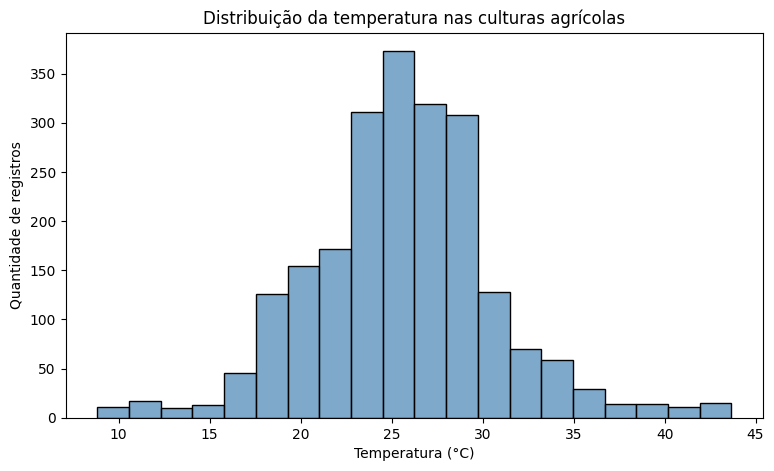

In [4]:
# Gráfico 1 — Distribuição da temperatura

plt.figure(figsize=(9, 5))

sns.histplot(
    data=dados,
    x="temperature",
    bins=20,
    color="#548db9"
)

plt.title("Distribuição da temperatura nas culturas agrícolas")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Quantidade de registros")

plt.show()

### Interpretação do Gráfico 1 — Histograma da temperatura

A distribuição mostra que a maior concentração dos registros está entre aproximadamente 23 °C e 30 °C, com temperatura média de 25,62 °C. Também aparecem temperaturas inferiores e superiores a esse intervalo, indicando variação nas condições registradas. Como a base reúne 2.200 observações de 22 culturas agrícolas, a média descreve o conjunto completo e não pode ser considerada a temperatura ideal para todas as culturas. Para uma análise mais específica, é necessário comparar cada cultura separadamente e considerar também as demais características do solo e do clima.


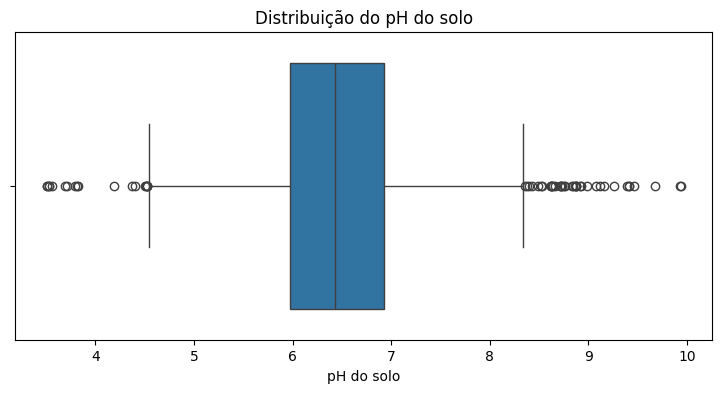

In [5]:
# Gráfico 2 — Distribuição do pH

plt.figure(figsize=(9, 4))

sns.boxplot(data=dados, x="ph")

plt.title("Distribuição do pH do solo")
plt.xlabel("pH do solo")

plt.show()

### Interpretação do Gráfico 2 — Distribuição do pH

> **Rascunho para revisão do grupo (redação assistida por IA):** verificar os dados, ajustar a linguagem e aprovar antes da entrega.

O boxplot mostra que o pH do solo apresenta mediana aproximada de **6,43**, com metade central dos registros entre **5,97 e 6,92** (primeiro e terceiro quartis). Também há observações fora do intervalo esperado pelos limites do boxplot, tanto com pH mais baixo quanto mais alto. Esses pontos são considerados atípicos do ponto de vista estatístico, mas não podem ser classificados automaticamente como erros de medição. Como os dados reúnem **22 culturas diferentes**, a distribuição geral não permite definir uma faixa de pH ideal para todas elas; essa avaliação exigiria uma análise por cultura e informações agronômicas adicionais.


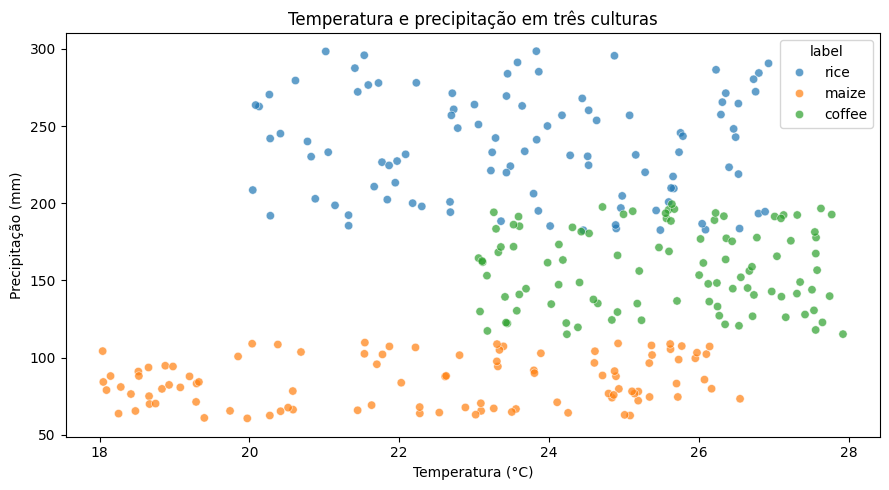

In [6]:
# Gráfico 3 — Relação entre temperatura e precipitação em três culturas
culturas = ["rice", "coffee", "maize"]
dados_filtrados = dados[dados["label"].isin(culturas)]

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=dados_filtrados,
    x="temperature",
    y="rainfall",
    hue="label",
    alpha=0.7,
)
plt.title("Temperatura e precipitação em três culturas")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Precipitação (mm)")
plt.tight_layout()
plt.show()

### Interpretação do Gráfico 3 — Temperatura × precipitação

> **Rascunho para revisão do grupo (redação assistida por IA):** verificar os dados, ajustar a linguagem e aprovar antes da entrega.

Ao comparar **arroz, milho e café** no gráfico de dispersão, observam-se diferenças mais evidentes na precipitação registrada do que na temperatura, embora existam sobreposições entre as culturas. No conjunto analisado, o **arroz** apresenta precipitação média de **236,18 mm**, seguido pelo **café**, com **158,07 mm**, e pelo **milho**, com **84,77 mm**. As temperaturas médias são **23,69 °C** para arroz, **25,54 °C** para café e **22,39 °C** para milho. A proximidade entre parte das temperaturas mostra que essa variável, isoladamente, não separa completamente as culturas. O gráfico identifica padrões presentes na amostra, mas não comprova causalidade nem define exigências ideais de cultivo; o período de referência da precipitação também não está especificado no CSV.


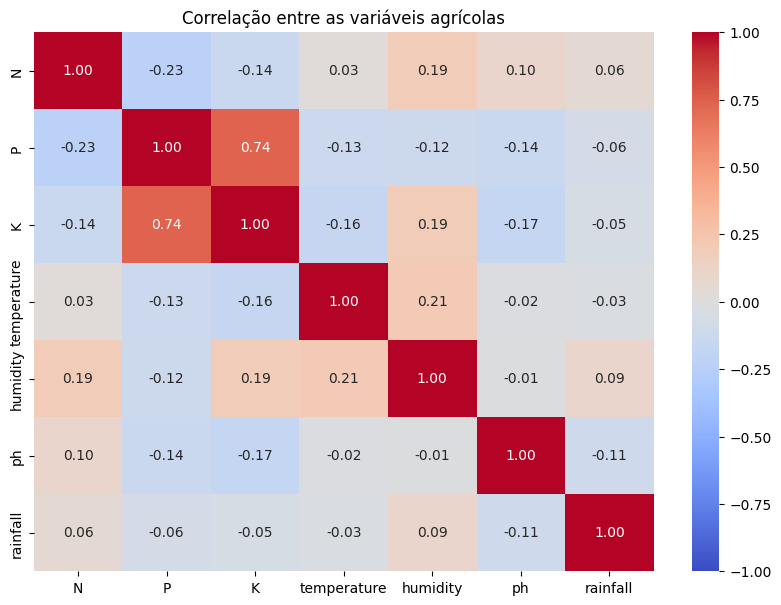

In [7]:

# Gráfico 4 — Mapa de calor de correlação

variaveis = [
    "N", "P", "K",
    "temperature", "humidity",
    "ph", "rainfall"
]

correlacao = dados[variaveis].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacao,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlação entre as variáveis agrícolas")

plt.show()


### Interpretação do Gráfico 4 — Mapa de calor

> **Rascunho para revisão do grupo (redação assistida por IA):** verificar os dados, ajustar a linguagem e aprovar antes da entrega.

O mapa de calor apresenta as **correlações lineares** entre as sete variáveis numéricas da base. A associação positiva mais destacada é entre **fósforo (P) e potássio (K)**, com coeficiente aproximado de **+0,74**, indicando que valores maiores de uma dessas variáveis tendem a acompanhar valores maiores da outra no conjunto de dados. A relação entre **nitrogênio (N) e fósforo (P)** é negativa e fraca, aproximadamente **−0,23**. Esses coeficientes não demonstram que uma variável cause alterações na outra. Além disso, por considerar as 22 culturas em conjunto, o mapa pode misturar diferenças entre culturas e ocultar relações específicas que apareceriam em análises separadas.


,N,P,K
label,,,
coffee,101.20,28.74,29.94
maize,77.76,48.44,19.79
rice,79.89,47.58,39.87


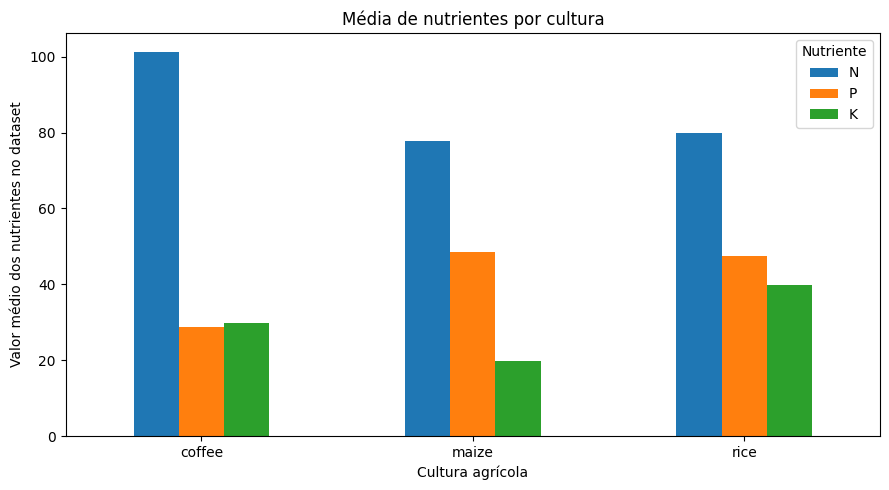

In [8]:

# Gráfico 5 — Comparação de nutrientes por cultura

culturas = ["rice", "coffee", "maize"]

dados_filtrados = dados[
    dados["label"].isin(culturas)
]

medias_nutrientes = dados_filtrados.groupby("label")[
    ["N", "P", "K"]
].mean()

display(medias_nutrientes.round(2))

medias_nutrientes.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Média de nutrientes por cultura")
plt.xlabel("Cultura agrícola")
plt.ylabel("Valor médio dos nutrientes no dataset")
plt.xticks(rotation=0)
plt.legend(title="Nutriente")
plt.tight_layout()

plt.show()


### Interpretação do Gráfico 5 — Nutrientes por cultura

> **Rascunho para revisão do grupo (redação assistida por IA):** verificar os dados, ajustar a linguagem e aprovar antes da entrega.

As médias de **N, P e K** diferem entre as três culturas selecionadas. O **café** apresenta a maior média de nitrogênio (**101,20**), acima do **arroz (79,89)** e do **milho (77,76)**. Para fósforo, o **milho (48,44)** e o **arroz (47,58)** têm médias próximas, enquanto o café apresenta **28,74**. Já o **arroz** possui a maior média de potássio (**39,87**), seguido do **café (29,94)** e do **milho (19,79)**. Portanto, as médias de potássio **não são equivalentes** entre as culturas. Os valores representam registros do dataset, não doses recomendadas de adubação; as unidades específicas dos nutrientes e o contexto de manejo não estão documentados no arquivo.


## 6. Comparação de três culturas

> **Rascunho para revisão do grupo (redação assistida por IA):** verificar os dados, ajustar a linguagem e aprovar antes da entrega.

Foram selecionados **arroz (`rice`), milho (`maize`) e café (`coffee`)**, com **100 registros por cultura**, para comparar perfis contrastantes de nutrientes do solo e condições climáticas presentes no conjunto de dados. As médias e os desvios-padrão da tabela abaixo descrevem as observações; **não representam condições universalmente ideais de plantio**.

**Solo e nutrientes.** O café apresenta média de **N = 101,20**, acima do arroz (**79,89**) e do milho (**77,76**). Para **K**, a maior média ocorre no arroz (**39,87**) e a menor no milho (**19,79**). O milho possui média de **P = 48,44**, próxima da observada no arroz (**47,58**), mas acima da do café (**28,74**). As médias de **pH** também variam: **6,79** no café, **6,43** no arroz e **6,25** no milho.

**Clima.** O arroz tem maior umidade média (**82,27%**) e precipitação média (**236,18 mm**) na amostra; o café apresenta **58,87%** e **158,07 mm**, e o milho, **65,09%** e **84,77 mm**. A temperatura média é maior no café (**25,54 °C**), seguida por arroz (**23,69 °C**) e milho (**22,39 °C**). Como algumas faixas de temperatura se sobrepõem, a interpretação deve considerar diferentes variáveis em conjunto. O CSV não especifica o período a que se referem os valores de precipitação.

**Limitação da comparação.** As médias refletem somente os registros disponíveis. Sem confirmação da procedência, da região, das unidades exatas de N/P/K e das condições de produção, não é possível convertê-las em recomendações de fertilizantes ou generalizá-las para lavouras brasileiras.


In [9]:
# Comparação descritiva: solo e clima para três culturas
# Os valores representam médias/desvios observados, não condições ideais de cultivo.
variaveis_comparacao = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
comparacao = dados[dados["label"].isin(["rice", "maize", "coffee"])]
display(comparacao.groupby("label")[variaveis_comparacao].mean().round(2))
display(comparacao.groupby("label")[variaveis_comparacao].std().round(2))

,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
coffee,101.20,28.74,29.94,25.54,58.87,6.79,158.07
maize,77.76,48.44,19.79,22.39,65.09,6.25,84.77
rice,79.89,47.58,39.87,23.69,82.27,6.43,236.18


,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
coffee,12.35,7.28,3.25,1.50,5.84,0.42,25.70
maize,11.95,8.01,2.94,2.68,5.45,0.41,15.55
rice,11.92,7.90,2.95,2.03,1.42,0.77,34.29


## 7. Preparação para Machine Learning

Entradas `X`: as sete variáveis numéricas. Alvo `y`: a cultura categórica (`label`). Divisão estratificada 80% treino / 20% teste, com semente fixa 42, preservando a representatividade das 22 culturas. 

**Prevenção de vazamento:** o escalonamento das variáveis é ajustado **somente dentro dos pipelines** de KNN, Regressão Logística e SVM, em cada partição de validação cruzada e depois no treino completo. Árvores e florestas não exigem escalonamento.


In [10]:
# Preparação reprodutível: 80% treino, 20% teste
# A variável-alvo não pode aparecer entre as entradas.
from sklearn.model_selection import train_test_split

atributos = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
X = dados[atributos]
y = dados["label"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEMENTE,
    stratify=y,
)
print("Treino:", X_treino.shape, "Teste:", X_teste.shape)
print("Exemplos por classe no treino:", sorted(y_treino.value_counts().unique()))
print("Exemplos por classe no teste:", sorted(y_teste.value_counts().unique()))

Treino: (1760, 7) Teste: (440, 7)
Exemplos por classe no treino: [np.int64(80)]
Exemplos por classe no teste: [np.int64(20)]


**Justificativa da preparação dos dados — rascunho para revisão do grupo:**

A divisão com `stratify=y` preserva a proporção de cada uma das **22 culturas** no treino e no teste. Como há **100 exemplos por classe**, a separação de **80%/20%** gera **80 exemplos de treinamento e 20 de teste por cultura**. Isso evita que a separação aleatória deixe alguma classe desproporcionalmente representada.

A padronização das variáveis deve ser ajustada apenas sobre os dados de treinamento, pois calcular média e desvio-padrão com o conjunto completo permitiria que informações do teste influenciassem o pré-processamento. O `StandardScaler` é usado dentro de `Pipeline` para que cada partição da validação cruzada aprenda suas transformações somente com a parte de treino.


## 8. Treinamento e seleção dos cinco algoritmos

Os modelos abaixo foram integrados a partir do notebook colaborativo `FarmTech_Fase3_IA.ipynb`:

| Modelo | Abordagem | Pré-processamento |
|---|---|---|
| Regressão Logística | Classificador linear multiclasse | `StandardScaler` no pipeline |
| KNN (k=5) | Voto dos vizinhos mais próximos | `StandardScaler` no pipeline |
| Árvore de Decisão | Regras hierárquicas | Sem escalonamento |
| Random Forest (200 árvores) | Conjunto de árvores | Sem escalonamento |
| SVM (RBF) | Fronteiras não lineares | `StandardScaler` no pipeline |

**Seleção metodológica:** o modelo de referência é escolhido usando **F1 macro médio em validação cruzada estratificada de cinco partes apenas sobre o treino**. A média de acurácia da validação cruzada também é exibida. O conjunto de teste fica reservado para a avaliação final e não é utilizado para escolher o modelo.


In [11]:
# Treinamento e seleção por validação cruzada SOMENTE no conjunto de treino
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

modelos = {
    "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEMENTE)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=SEMENTE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEMENTE),
    "SVM": make_pipeline(StandardScaler(), SVC()),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
linhas_cv = []
for nome, modelo in modelos.items():
    notas = cross_validate(
        modelo, X_treino, y_treino, cv=cv,
        scoring={"f1": "f1_macro", "acuracia": "accuracy"},
        return_train_score=False,
    )
    linhas_cv.append({
        "Modelo": nome,
        "CV F1 macro (média)": notas["test_f1"].mean(),
        "CV F1 macro (desvio)": notas["test_f1"].std(),
        "CV acurácia (média)": notas["test_acuracia"].mean(),
    })

comparacao_cv = pd.DataFrame(linhas_cv).sort_values(
    ["CV F1 macro (média)", "CV acurácia (média)"], ascending=False
).reset_index(drop=True)
modelo_escolhido = comparacao_cv.loc[0, "Modelo"]
print("Comparação APENAS no treino (5 folds estratificados):")
display(comparacao_cv.round(4))
print("Modelo escolhido pela CV no treino:", modelo_escolhido)


Comparação APENAS no treino (5 folds estratificados):


,Modelo,CV F1 macro (média),CV F1 macro (desvio),CV acurácia (média)
0,Random Forest,0.9943,0.0048,0.9943
1,Árvore de Decisão,0.9852,0.0068,0.9852
2,SVM,0.9788,0.0106,0.9790
3,Regressão Logística,0.9678,0.0068,0.9682
4,KNN,0.9650,0.0124,0.9653


Modelo escolhido pela CV no treino: Random Forest


## 9. Avaliação no conjunto de teste e diagnóstico de erros

Depois da seleção feita no treino, cada algoritmo é ajustado com os 1.760 registros de treino e avaliado sobre o **mesmo conjunto de 440 registros de teste**, permitindo comparar acurácia, precisão macro, recall macro e F1 macro. A classificação multiclasse e a matriz de confusão do modelo **selecionado por validação cruzada** mostram os erros por cultura.

**Não selecionar novamente pelo teste:** a tabela de teste descreve desempenho final, mas não deve ser usada para mudar o modelo selecionado ou ajustar parâmetros.


Desempenho no teste (ordenado pela seleção feita no treino):


,Modelo,Acurácia,Precisão macro,Recall macro,F1 macro
0,Random Forest,0.9955,0.9957,0.9955,0.9955
1,Árvore de Decisão,0.9795,0.9806,0.9795,0.9794
2,SVM,0.9841,0.9856,0.9841,0.9840
3,Regressão Logística,0.9727,0.9740,0.9727,0.9725
4,KNN,0.9795,0.9804,0.9795,0.9793


Modelo selecionado ANTES do teste: Random Forest


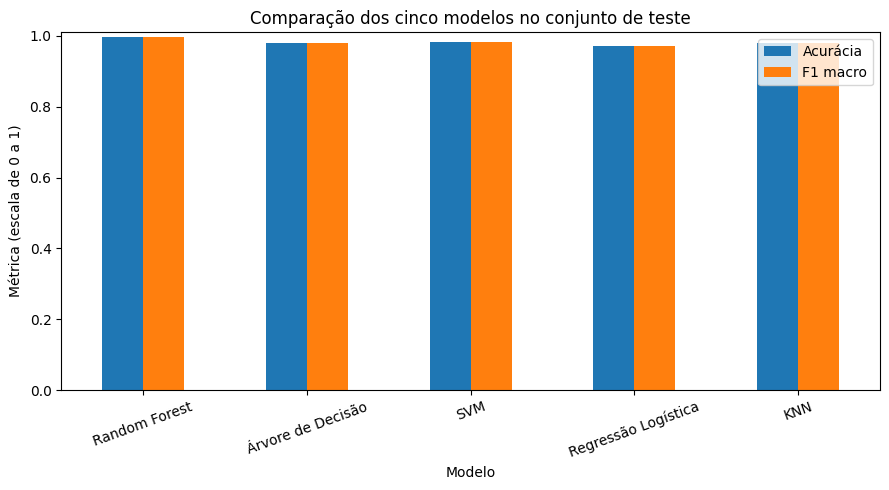

In [12]:
# Avaliação final: conjunto de teste reservado, sem seleção baseada nas notas de teste.
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
)

modelos_ajustados = {}
linhas_teste = []
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    modelos_ajustados[nome] = modelo
    previsoes = modelo.predict(X_teste)
    linhas_teste.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, previsoes),
        "Precisão macro": precision_score(y_teste, previsoes, average="macro", zero_division=0),
        "Recall macro": recall_score(y_teste, previsoes, average="macro", zero_division=0),
        "F1 macro": f1_score(y_teste, previsoes, average="macro", zero_division=0),
    })

resultados_teste = pd.DataFrame(linhas_teste)
resultados_teste = comparacao_cv[["Modelo"]].merge(resultados_teste, on="Modelo", how="left")
print("Desempenho no teste (ordenado pela seleção feita no treino):")
display(resultados_teste.round(4))
print("Modelo selecionado ANTES do teste:", modelo_escolhido)

ax = resultados_teste.set_index("Modelo")[["Acurácia", "F1 macro"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1.01), rot=20
)
ax.set_title("Comparação dos cinco modelos no conjunto de teste")
ax.set_ylabel("Métrica (escala de 0 a 1)")
plt.tight_layout()
plt.show()


### 9.1 Relatório de classificação e matriz de confusão do modelo selecionado

Use o relatório com quatro casas decimais para identificar diferenças que o arredondamento para 1,00 esconderia. O mapa deve ser interpretado como **predição de classes no dataset**, não validação agronômica externa.


Modelo selecionado pela CV: Random Forest
              precision    recall  f1-score   support

       apple     1.0000    1.0000    1.0000        20
      banana     1.0000    1.0000    1.0000        20
   blackgram     1.0000    0.9500    0.9744        20
    chickpea     1.0000    1.0000    1.0000        20
     coconut     1.0000    1.0000    1.0000        20
      coffee     1.0000    1.0000    1.0000        20
      cotton     1.0000    1.0000    1.0000        20
      grapes     1.0000    1.0000    1.0000        20
        jute     0.9524    1.0000    0.9756        20
 kidneybeans     1.0000    1.0000    1.0000        20
      lentil     1.0000    1.0000    1.0000        20
       maize     0.9524    1.0000    0.9756        20
       mango     1.0000    1.0000    1.0000        20
   mothbeans     1.0000    1.0000    1.0000        20
    mungbean     1.0000    1.0000    1.0000        20
   muskmelon     1.0000    1.0000    1.0000        20
      orange     1.0000    1.0000    1.

,real,previsto,quantidade
0,blackgram,maize,1
1,rice,jute,1


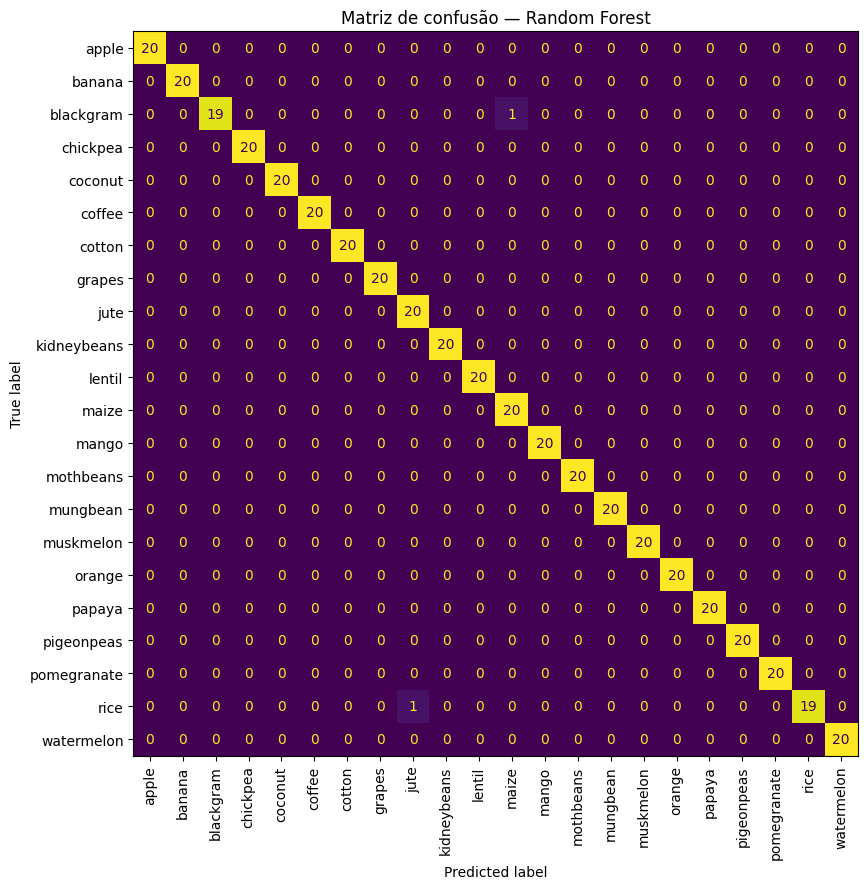

In [13]:
modelo_selecionado = modelos_ajustados[modelo_escolhido]
previsoes_selecionado = modelo_selecionado.predict(X_teste)
print("Modelo selecionado pela CV:", modelo_escolhido)
print(classification_report(y_teste, previsoes_selecionado, digits=4, zero_division=0))

erros = pd.DataFrame({"real": y_teste.to_numpy(), "previsto": previsoes_selecionado})
erros = erros.loc[erros["real"] != erros["previsto"]]
print("Erros no conjunto de teste:", len(erros), "de", len(y_teste))
if not erros.empty:
    display(erros.value_counts().rename("quantidade").reset_index())

fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(
    y_teste, previsoes_selecionado, ax=ax, xticks_rotation=90, colorbar=False
)
ax.set_title("Matriz de confusão — " + modelo_escolhido)
plt.tight_layout()
plt.show()


### Discussão dos resultados e dos erros

> **Rascunho para revisão do grupo (redação assistida por IA):** verificar os dados, ajustar a linguagem e aprovar antes da entrega.

A seleção do modelo foi realizada pelo **F1 macro médio em validação cruzada estratificada com cinco partições**, utilizando somente os dados de treinamento. O algoritmo selecionado foi o **Random Forest**. Na avaliação final, ele acertou **438 dos 440 exemplos de teste**, alcançando **acurácia de 99,55%** e **F1 macro de 0,9955**. O relatório de classificação e a matriz de confusão revelaram **dois erros**: um registro de **`blackgram`** foi classificado como **`maize`**, e um registro de **`rice`** foi classificado como **`jute`**. Não há evidências suficientes para afirmar que essas duas confusões sejam sistemáticas.

As métricas mostram bom desempenho **nessa divisão específica do dataset**, mas não garantem o mesmo resultado fora da amostra. O conjunto contém 100 registros por cultura e sua procedência primária não foi confirmada; também não há validação independente por região, safra ou propriedade. Acurácia elevada em dados de aula não equivale a validação agronômica nem assegura desempenho em propriedades brasileiras.


### 9.2 Importância das variáveis no Random Forest

Independente do modelo escolhido na validação cruzada, podemos inspecionar o Random Forest como ferramenta exploratória. A importância baseada em redução de impureza pode ser enviesada para determinados tipos de variável e **não significa causa e efeito**.


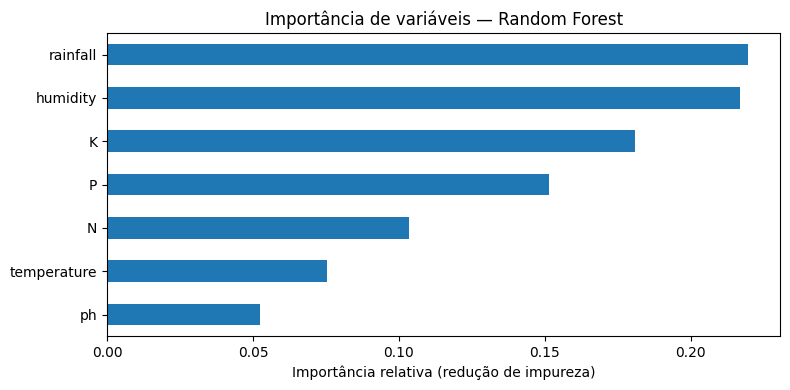

,Importância
rainfall,0.2196
humidity,0.2171
K,0.1808
P,0.1513
N,0.1034
temperature,0.0755
ph,0.0523


In [14]:
floresta = modelos_ajustados["Random Forest"]
importancia = pd.Series(floresta.feature_importances_, index=X_treino.columns).sort_values()
ax = importancia.plot(kind="barh", figsize=(8, 4), title="Importância de variáveis — Random Forest")
ax.set_xlabel("Importância relativa (redução de impureza)")
plt.tight_layout()
plt.show()
display(importancia.sort_values(ascending=False).round(4).rename("Importância").to_frame())


### Interpretação da importância das variáveis

> **Rascunho para revisão do grupo (redação assistida por IA):** verificar os dados, ajustar a linguagem e aprovar antes da entrega.

No Random Forest, as maiores importâncias relativas calculadas por redução de impureza foram **precipitação (`rainfall`: 0,2196)** e **umidade (`humidity`: 0,2171)**, seguidas por **potássio (`K`: 0,1808)** e **fósforo (`P`: 0,1513)**. Esse resultado sugere que, nesta base, essas variáveis contribuíram mais para as decisões das árvores. A análise exploratória também mostrou diferenças expressivas de precipitação entre arroz, café e milho. Entretanto, a medida de importância **não demonstra causalidade**, não permite afirmar uma necessidade agronômica universal e pode sofrer vieses do próprio método baseado em árvores.


### 9.3 Demonstração de uma previsão

O exemplo usa uma observação do conjunto de teste para demonstrar a interface do classificador. É uma **predição experimental**, não uma indicação de plantio para o mundo real.


In [15]:
exemplo = X_teste.iloc[[0]]
print("Condições do exemplo (conjunto de teste):")
display(exemplo)
print("Cultura prevista pelo modelo:", modelo_selecionado.predict(exemplo)[0])
print("Classe real registrada:       ", y_teste.iloc[0])


Condições do exemplo (conjunto de teste):


,N,P,K,temperature,humidity,ph,rainfall
1609,13,23,6,23.961476,90.26408,7.365338,102.69587


Cultura prevista pelo modelo: orange
Classe real registrada:        orange


## 10. Conclusão acadêmica — RASCUNHO PARA REVISÃO DO GRUPO

Este trabalho analisou um conjunto de **2.200 registros de 22 culturas agrícolas** com sete atributos numéricos de solo e clima, buscando compreender padrões nos dados e comparar algoritmos de classificação multiclasse. A análise exploratória mostrou concentração de temperaturas aproximadamente entre **23 °C e 30 °C**, pH mediano de **6,43** e associação positiva entre fósforo e potássio (**r ≈ 0,74**). A comparação de arroz, milho e café revelou diferenças nos nutrientes e nas condições climáticas registradas, especialmente nas médias de precipitação e umidade.

Foram avaliados **Regressão Logística, KNN, Árvore de Decisão, Random Forest e SVM**, mantendo a mesma divisão estratificada de **1.760 registros para treino e 440 para teste**. A seleção por validação cruzada ocorreu somente no treinamento, e o **Random Forest** foi o modelo escolhido. No teste, obteve **99,55% de acurácia** e **F1 macro de 0,9955**, com dois erros de classificação. Esses números indicam bom desempenho neste experimento, sem comprovar que o algoritmo seja necessariamente o melhor em outros conjuntos.

Como limitações, destacam-se a **origem primária ainda não confirmada do CSV**, a ausência de informações completas sobre região, período e coleta dos dados e a falta de avaliação com amostras externas de propriedades agrícolas brasileiras. As saídas do classificador devem ser entendidas como **predições experimentais de classes**, e não como recomendações agronômicas prontas para uso. Uma continuidade apropriada seria testar o método com dados locais, documentados e validados por profissionais da área, além de verificar estabilidade entre diferentes períodos e regiões.

> **Antes da entrega:** o grupo deve revisar criticamente esta conclusão, verificar as referências e conferir as regras de autoria e identificação acadêmica da FIAP.


## 11. Referências e atribuições

- Arquivo CSV recebido como material da atividade FIAP: `Atividade_Cap11_produtos_agricolas(2).csv` (origem primária e permissão de redistribuição a confirmar).
- Dataset público compatível para contextualização, **sem identidade comprovada com o CSV da atividade**: https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset
- Documentação do scikit-learn (pipelines, validação cruzada, métricas): https://scikit-learn.org/stable/
- Documentação do pandas: https://pandas.pydata.org/docs/
- Documentação do seaborn: https://seaborn.pydata.org/
- **Contribuições da equipe:** gráficos, análise exploratória e comparações integradas a partir do notebook principal; implementação-base de cinco classificadores incorporada de `FarmTech_Fase3_IA.ipynb`, compartilhado por integrante do grupo; correções metodológicas realizadas durante a integração. Conferir nomes, RMs e regras de autoria acadêmica da entrega antes de enviar.
